In [ ]:
#importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import accuracy_score

import seaborn as sns

#avoid warning messages
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Exploratory Data Analysis (EDA)

In [ ]:
# read dataset from a public Google Drive File

file_link = 'https://drive.google.com/file/d/1iiheYOJIkqf5D91gDQXn9GSxuF4vRVd6/view'

# get the id part of the file
id = file_link.split("/")[-2]

# creating a new link using the id for better readability of csv file in pandas
new_link = f'https://drive.google.com/uc?id={id}'
df = pd.read_csv(new_link)

# let's look at the first few instances
df.head()


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
df.shape

(1470, 35)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [ ]:
df.describe(include='all')

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470,1470,1470.000000,1470,1470.000000,1470.000000,1470,1470.0,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
unique,NaN,2,3,NaN,3,NaN,NaN,6,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,No,Travel_Rarely,NaN,Research & Development,NaN,NaN,Life Sciences,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1233,1043,NaN,961,NaN,NaN,606,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,36.923810,NaN,NaN,802.485714,NaN,9.192517,2.912925,NaN,1.0,1024.865306,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,NaN,NaN,403.509100,NaN,8.106864,1.024165,NaN,0.0,602.024335,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,NaN,NaN,102.000000,NaN,1.000000,1.000000,NaN,1.0,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,NaN,NaN,465.000000,NaN,2.000000,2.000000,NaN,1.0,491.250000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,NaN,NaN,802.000000,NaN,7.000000,3.000000,NaN,1.0,1020.500000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,NaN,NaN,1157.000000,NaN,14.000000,4.000000,NaN,1.0,1555.750000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000


In [ ]:
df.nunique()

,0
Age,43
Attrition,2
BusinessTravel,3
DailyRate,886
Department,3
DistanceFromHome,29
Education,5
EducationField,6
EmployeeCount,1
EmployeeNumber,1470


In [ ]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [ ]:
cat_cols=df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Categorical Variables:")
print(cat_cols)
print("Numerical Variables:")
print(num_cols)

Categorical Variables:
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']
Numerical Variables:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


Attrition
No     1233
Yes     237
Name: count, dtype: int64


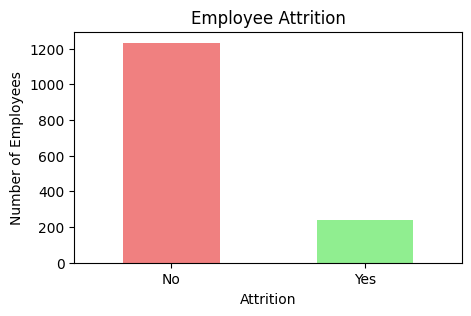

In [ ]:
# Check counts of Attrition values
print(df['Attrition'].value_counts())

# Plot bar chart
plt.figure(figsize=(5, 3))
df['Attrition'].value_counts().plot(kind='bar', color=['lightcoral', 'lightgreen'])
plt.title('Employee Attrition')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)
plt.show()


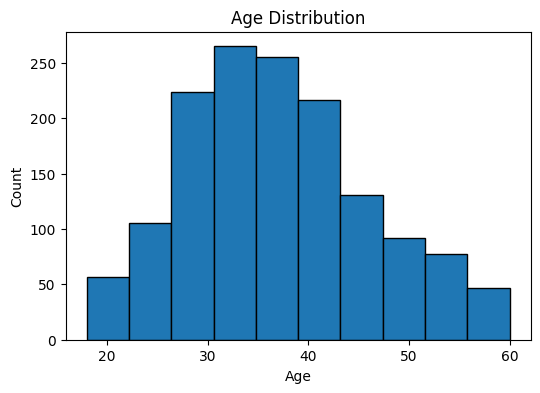

In [ ]:
# Visualize the distribution of 'Age' variable
plt.figure(figsize=(6, 4))
plt.hist(df['Age'].dropna(), edgecolor='black')
# dropna eliminates the null/missing values but not in df
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

Gender
Male      882
Female    588
Name: count, dtype: int64


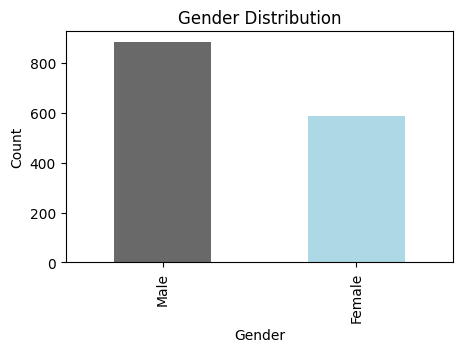

In [ ]:
# Visualize the distribution of 'Gender' variable
print(df.value_counts('Gender'))

plt.figure(figsize=(5, 3))
df['Gender'].value_counts().plot(kind='bar', color=['dimgray', 'lightblue'])
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.show()

<Figure size 600x400 with 0 Axes>

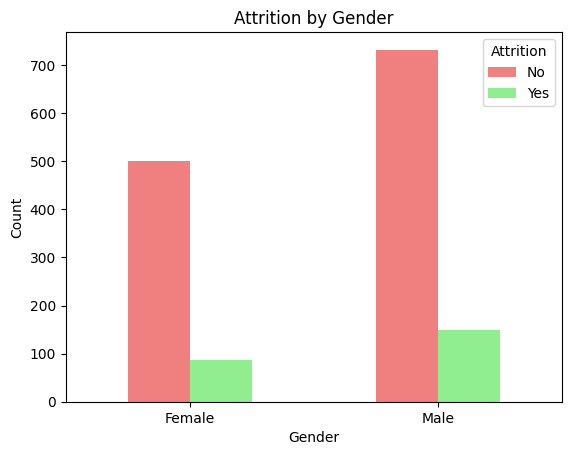

In [ ]:
#Visualize the relationship between 'Gender' and 'Attrition'

plt.figure(figsize=(6, 4))
pd.crosstab(df['Gender'], df['Attrition']).plot(kind='bar', color=['lightcoral', 'lightgreen'])
plt.title('Attrition by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

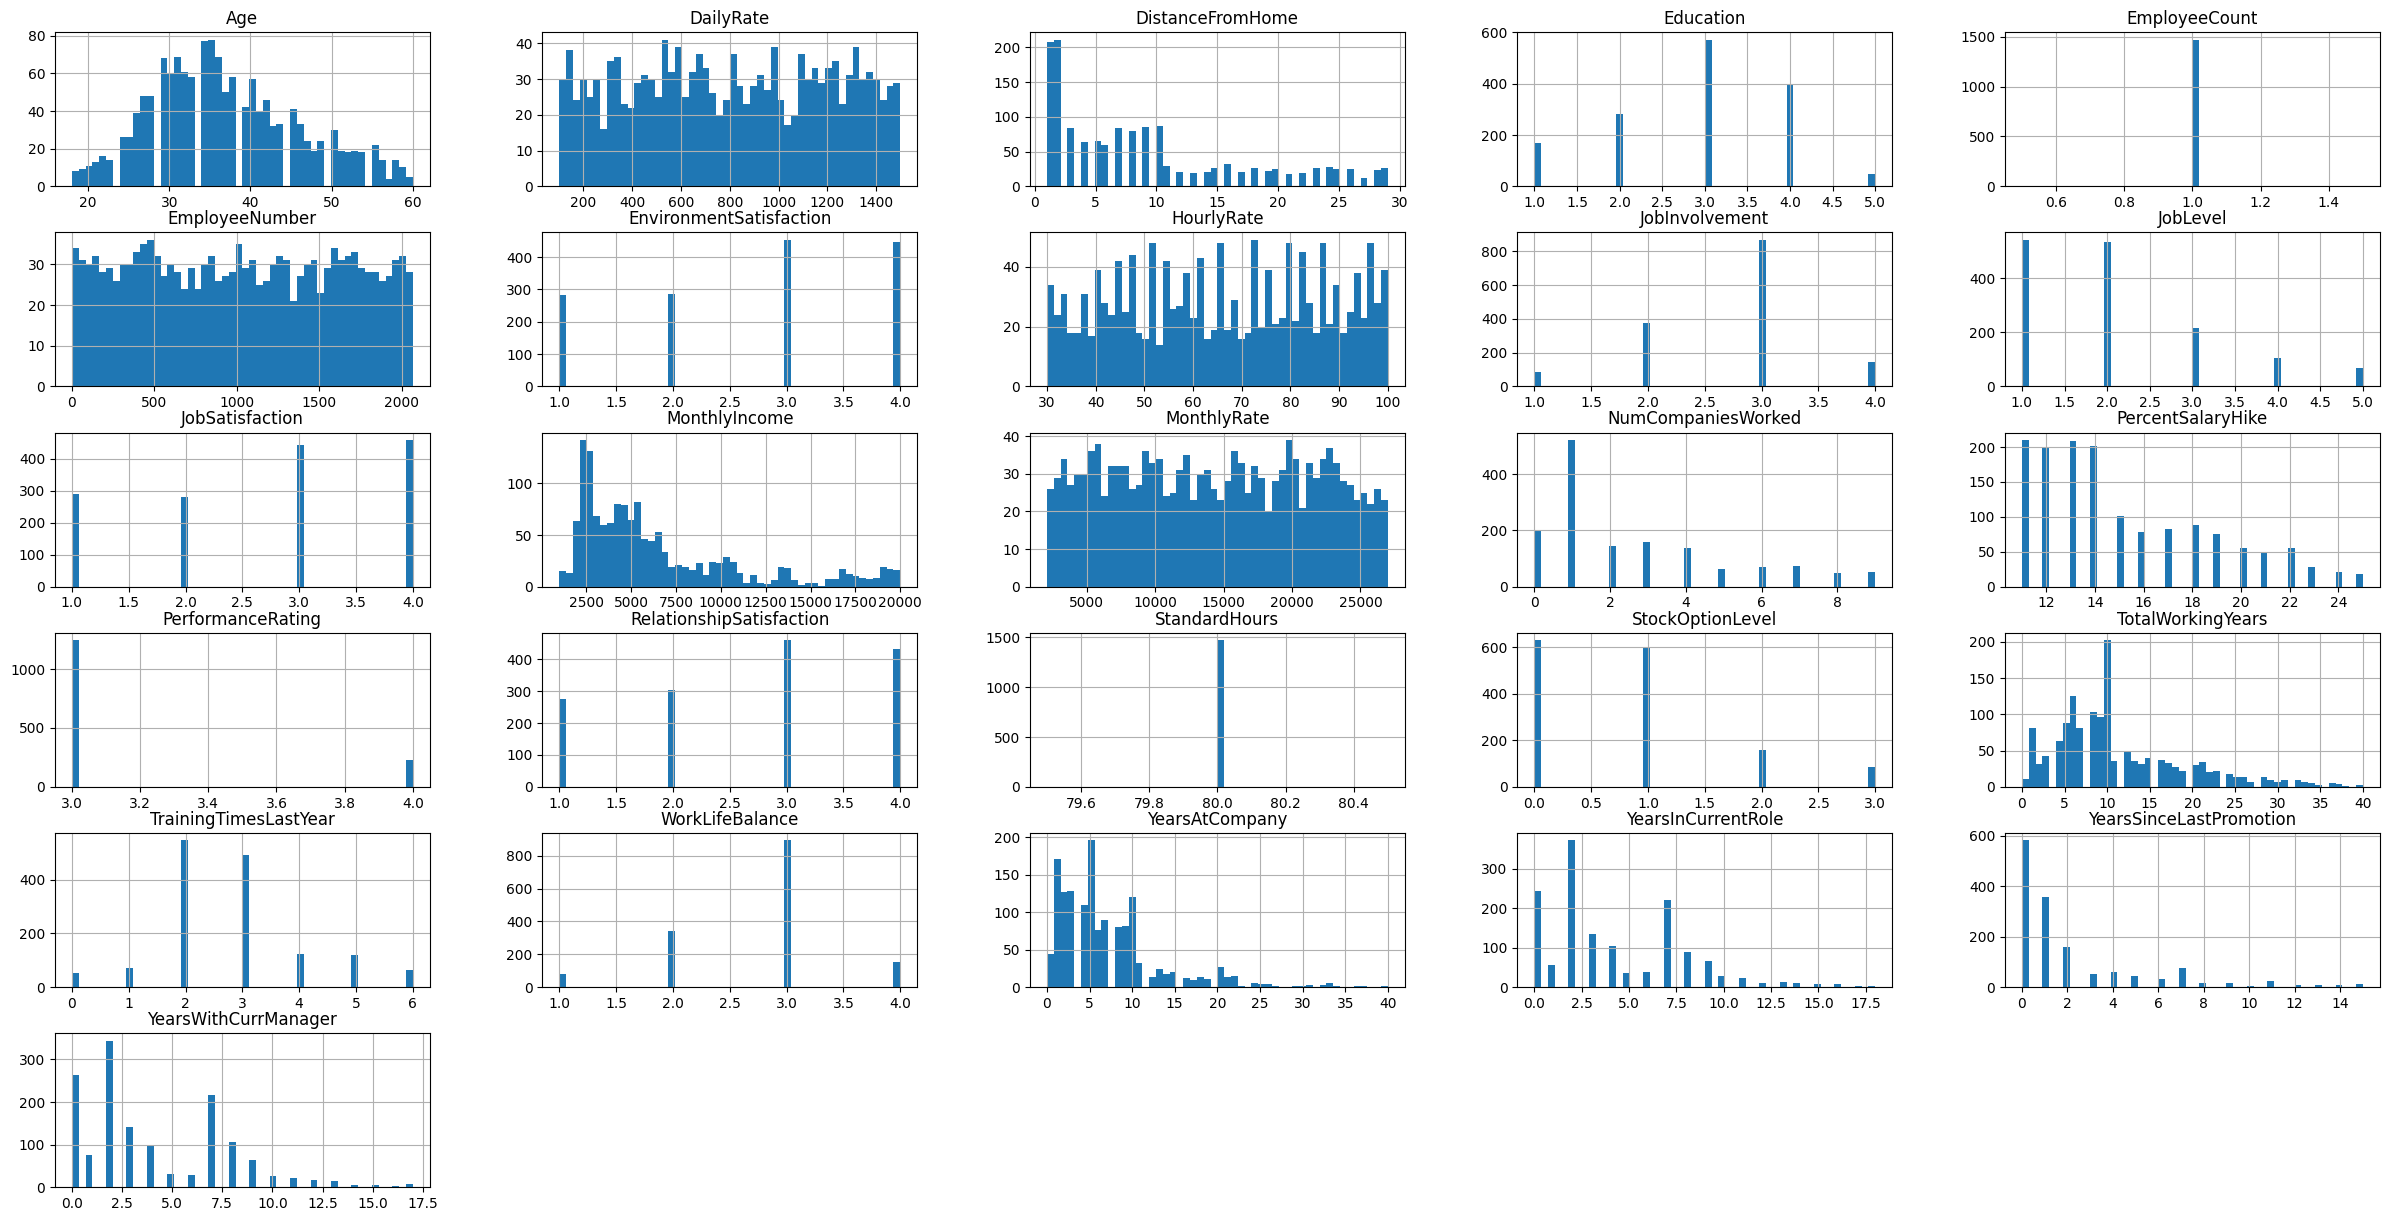

In [ ]:
#Visual Representation of The Numeric Data via Histogram
numerical_DATA = df.select_dtypes(include='number')

fig, ax = plt.subplots(figsize=(30, 15), facecolor='white')
numerical_DATA.hist(bins=50, ax=ax)
ax.set_facecolor('green')
plt.show()

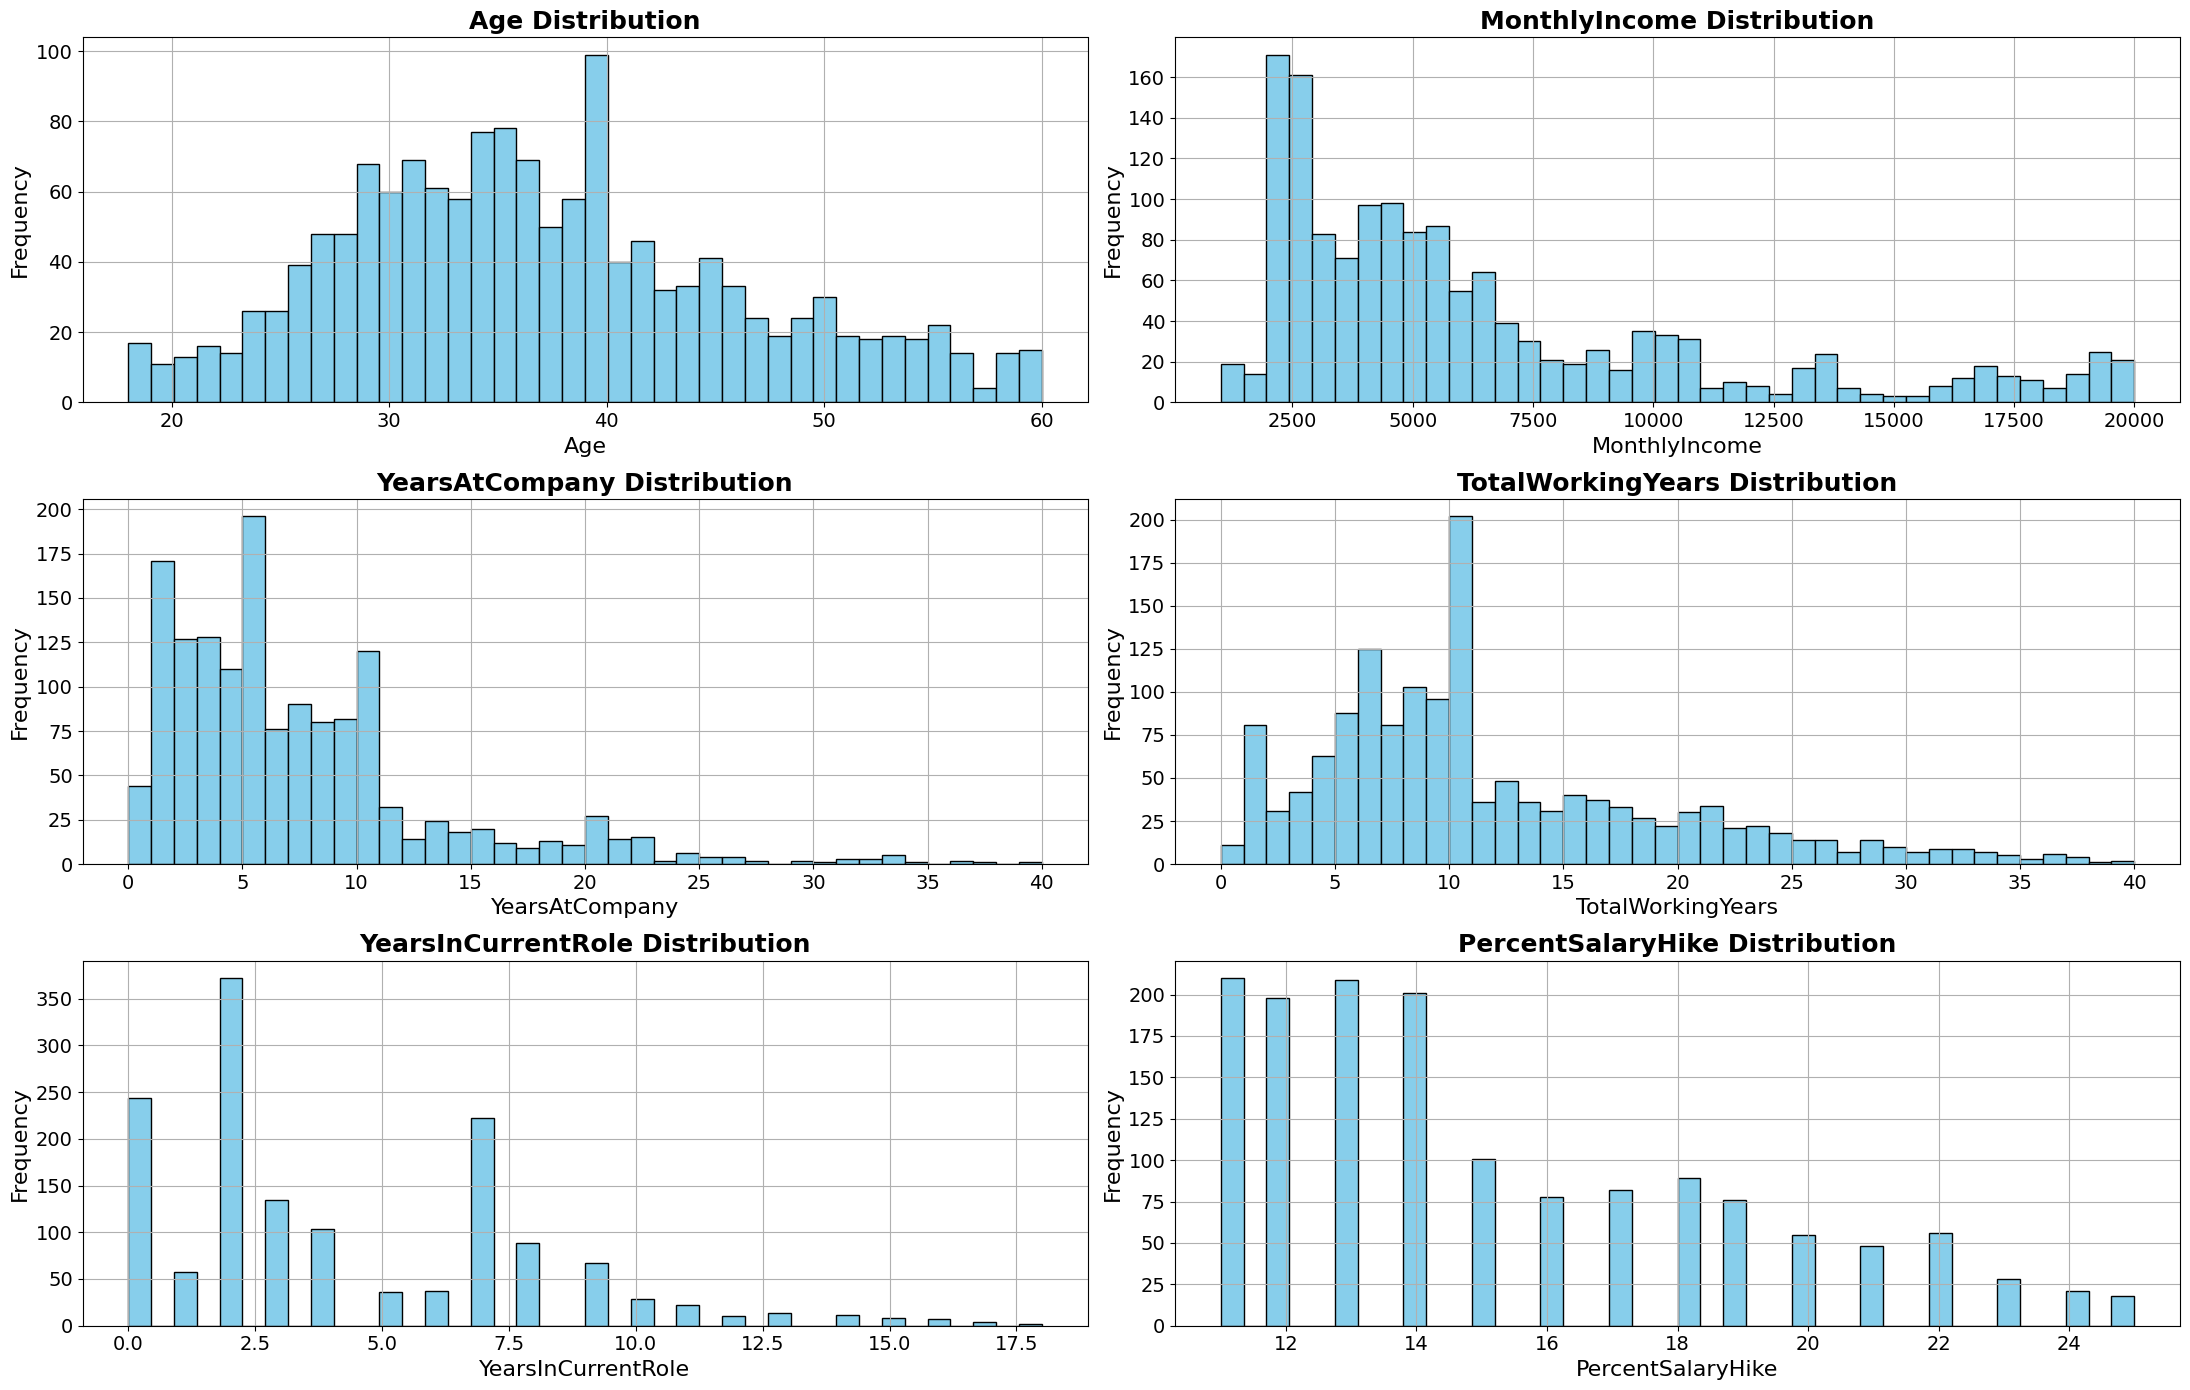

In [ ]:
# Visual Representation of Selected Numeric Data via Histogram
important_numeric_cols = ['Age', 'MonthlyIncome', 'YearsAtCompany', 'TotalWorkingYears', 'YearsInCurrentRole', 'PercentSalaryHike']

plt.figure(figsize=(22, 14))

for i, col in enumerate(important_numeric_cols, 1):
    plt.subplot(3, 2, i)  # 3 rows, 2 cols layout
    df[col].hist(bins=40, color='skyblue', edgecolor='black')
    plt.title(f'{col} Distribution', fontsize=18, fontweight='bold')
    plt.xlabel(col, fontsize=16)
    plt.ylabel('Frequency', fontsize=16)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)

plt.tight_layout()
plt.show()


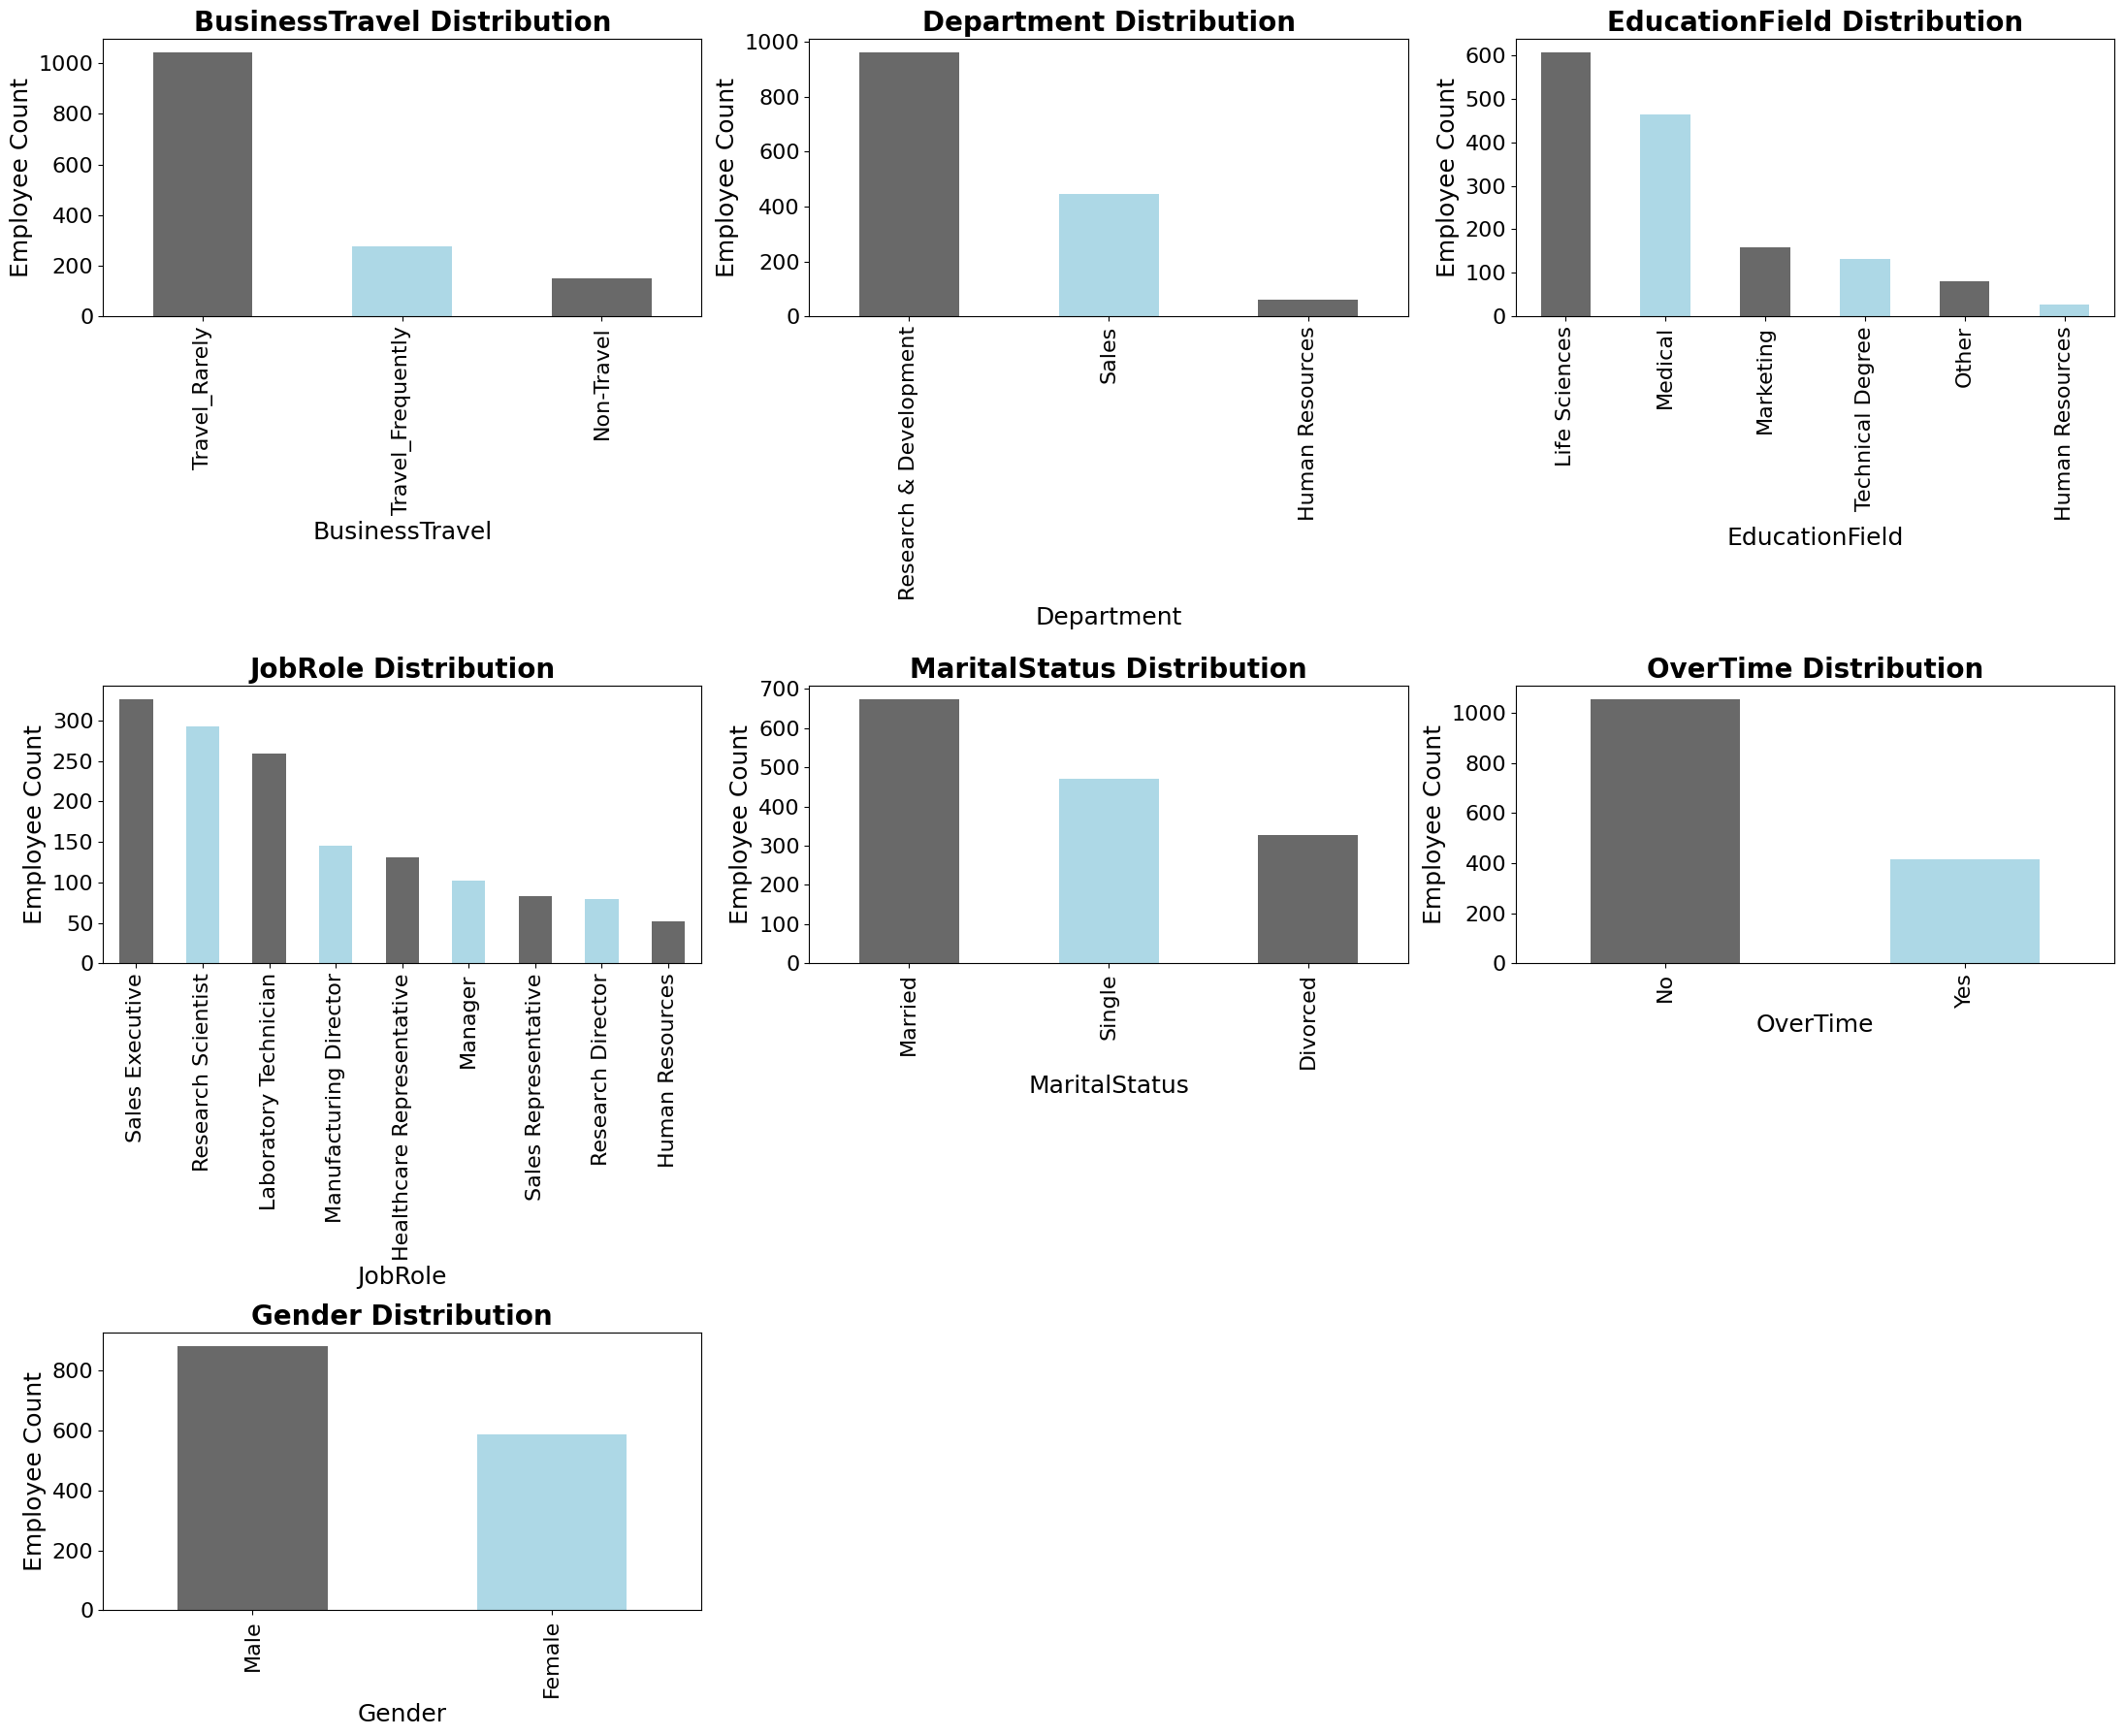

In [ ]:
# Visualize the distribution of categorical variables
categorical_cols = ['BusinessTravel', 'Department', 'EducationField','JobRole', 'MaritalStatus', 'OverTime', 'Gender']

plt.figure(figsize=(22, 18))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(3, 3, i)
    df[col].value_counts().plot(kind='bar', color=['dimgray', 'lightblue'])
    plt.title(f'{col} Distribution', fontsize=20, fontweight='bold')
    plt.xlabel(col, fontsize=18)
    plt.ylabel('Employee Count', fontsize=18)
    plt.xticks(rotation=90, fontsize=16)
    plt.yticks(fontsize=16)

plt.tight_layout()
plt.show()


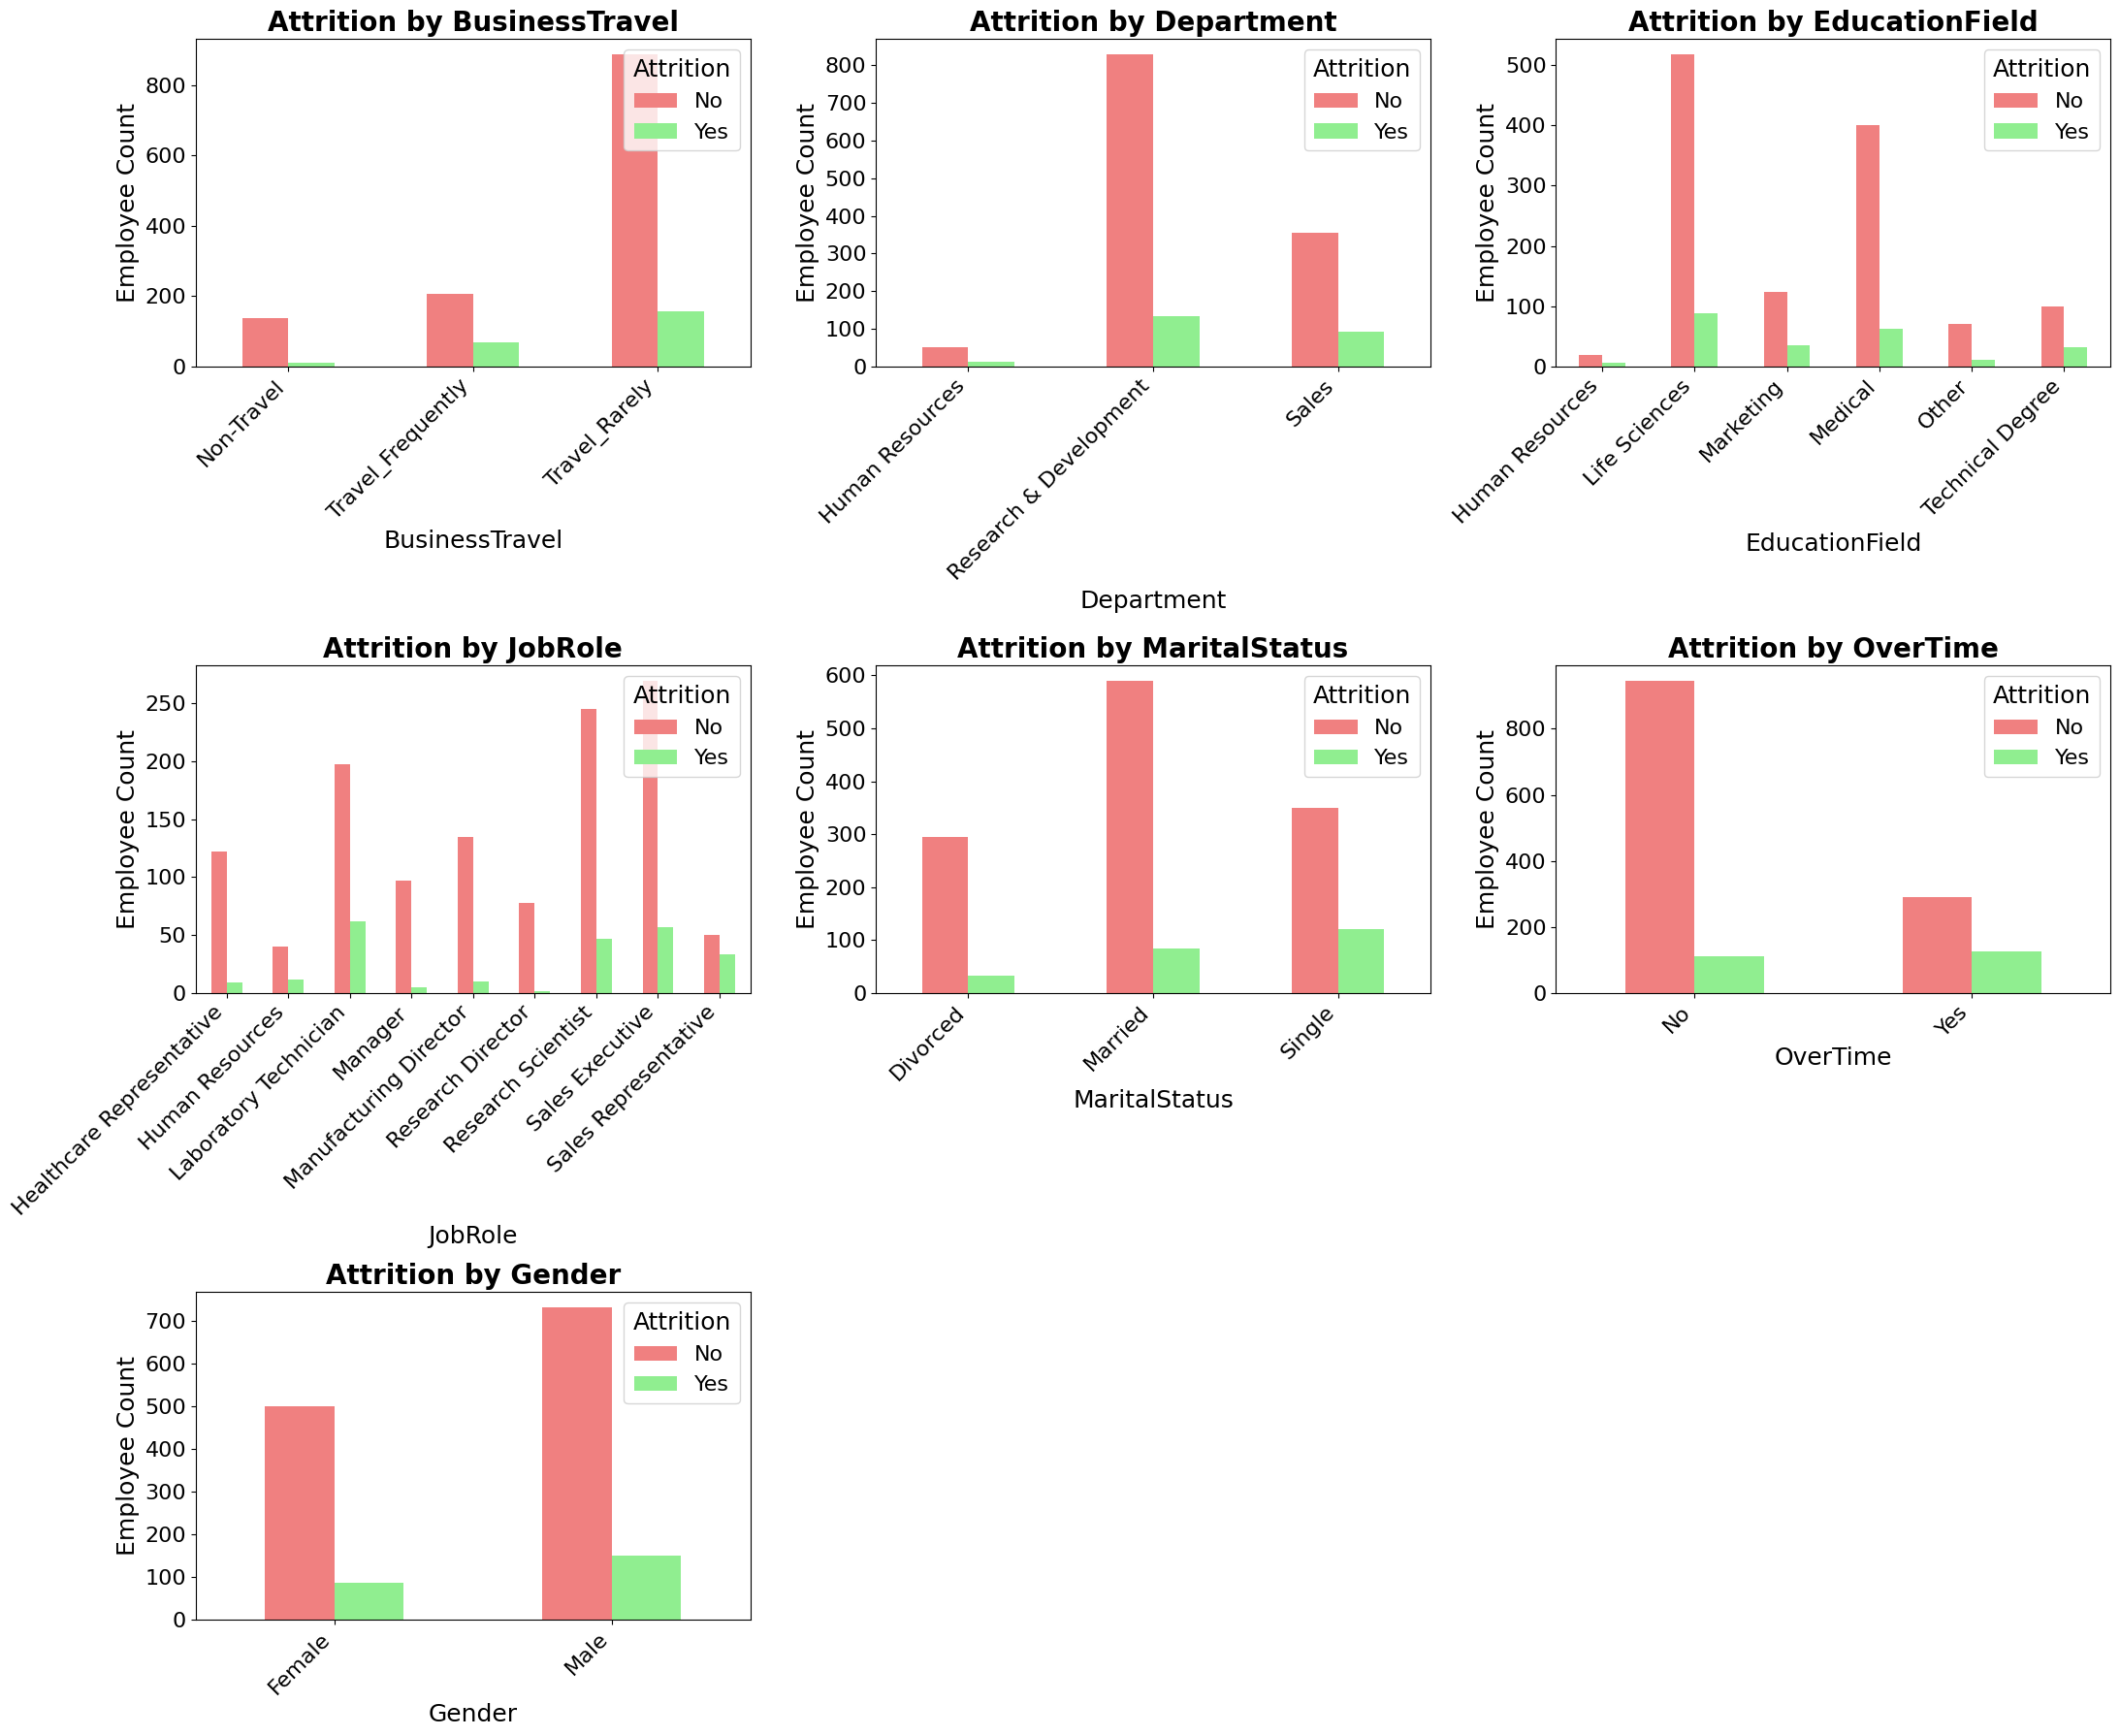

In [ ]:
# Visualize the relationship between categorical columns and 'Attrition'
categorical_cols = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus', 'OverTime', 'Gender']

plt.figure(figsize=(22, 18))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(3, 3, i)  # 3 rows, 3 columns layout
    pd.crosstab(df[col], df['Attrition']).plot(
        kind='bar',
        color=['lightcoral', 'lightgreen'],
        ax=plt.gca()
    )
    plt.title(f'Attrition by {col}', fontsize=20, fontweight='bold')
    plt.xlabel(col, fontsize=18)
    plt.ylabel('Employee Count', fontsize=18)
    plt.xticks(rotation=45, ha='right', fontsize=16)
    plt.yticks(fontsize=16)
    plt.legend(title='Attrition', loc='upper right', fontsize=16, title_fontsize=18)

plt.tight_layout()
plt.show()


<Figure size 800x600 with 0 Axes>

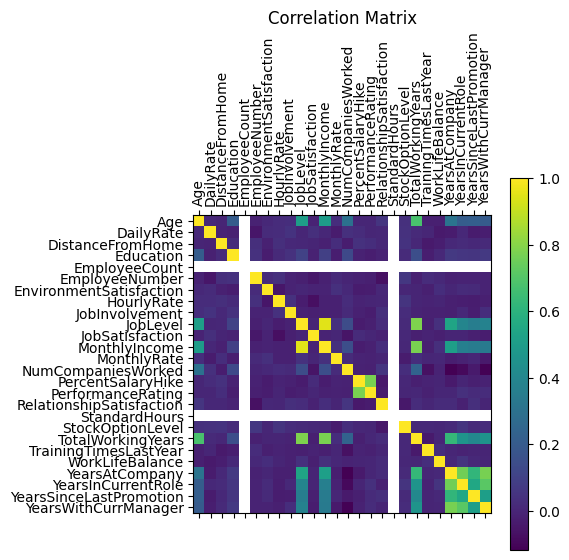

In [ ]:
# Correlation matrix plot
plt.figure(figsize=(8, 6))
correlation_matrix = df.corr(numeric_only=True)
# print(correlation_matrix)
plt.matshow(correlation_matrix)
plt.title('Correlation Matrix')
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)
plt.colorbar()
plt.show()

## Data Prepocessing

In [ ]:
# Drop redundant features/columns
df = df.drop(columns=['EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours'], errors='ignore')
df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,3,Male,...,3,3,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,4,Male,...,3,1,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,2,Male,...,4,2,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,4,Male,...,3,4,0,17,3,2,9,6,0,8


In [ ]:
#Total Number of Duplicated Rows and Columns
print(f"Duplicated Rows: {df.duplicated().sum()}")
print(f'Duplicated Columns: {df.T.duplicated().sum()}')

Duplicated Rows: 0
Duplicated Columns: 0


In [ ]:
# Convert categorical variables to numerical (one-hot encoding)
df = pd.get_dummies(df, columns=['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'Gender', 'MaritalStatus', 'OverTime'])
df

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,Gender_Female,Gender_Male,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,OverTime_No,OverTime_Yes
0,41,Yes,1102,1,2,2,94,3,2,4,...,False,True,False,True,False,False,False,True,False,True
1,49,No,279,8,1,3,61,2,2,2,...,True,False,False,False,True,False,True,False,True,False
2,37,Yes,1373,2,2,4,92,2,1,3,...,False,False,False,False,True,False,False,True,False,True
3,33,No,1392,3,4,4,56,3,1,3,...,True,False,False,True,False,False,True,False,False,True
4,27,No,591,2,1,1,40,3,1,2,...,False,False,False,False,True,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,884,23,2,3,41,4,2,4,...,False,False,False,False,True,False,True,False,True,False
1466,39,No,613,6,1,4,42,2,3,1,...,False,False,False,False,True,False,True,False,True,False
1467,27,No,155,4,3,2,87,4,2,2,...,False,False,False,False,True,False,True,False,False,True
1468,49,No,1023,2,3,4,63,2,2,2,...,False,True,False,False,True,False,True,False,True,False


In [ ]:
# Encode target variable Attrition (Yes=1, No=0)
if df['Attrition'].dtype == 'object':
    df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})
df

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,Gender_Female,Gender_Male,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,OverTime_No,OverTime_Yes
0,41,1,1102,1,2,2,94,3,2,4,...,False,True,False,True,False,False,False,True,False,True
1,49,0,279,8,1,3,61,2,2,2,...,True,False,False,False,True,False,True,False,True,False
2,37,1,1373,2,2,4,92,2,1,3,...,False,False,False,False,True,False,False,True,False,True
3,33,0,1392,3,4,4,56,3,1,3,...,True,False,False,True,False,False,True,False,False,True
4,27,0,591,2,1,1,40,3,1,2,...,False,False,False,False,True,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,0,884,23,2,3,41,4,2,4,...,False,False,False,False,True,False,True,False,True,False
1466,39,0,613,6,1,4,42,2,3,1,...,False,False,False,False,True,False,True,False,True,False
1467,27,0,155,4,3,2,87,4,2,2,...,False,False,False,False,True,False,True,False,False,True
1468,49,0,1023,2,3,4,63,2,2,2,...,False,True,False,False,True,False,True,False,True,False


# **Models**

In [ ]:
# Split the data into 80-20 train-test split

X = df.drop(['Attrition'], axis=1) # features
y = df['Attrition'] # target column

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# display the shapes

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1176, 51)
X_test shape: (294, 51)
y_train shape: (1176,)
y_test shape: (294,)


# Decision Tree

Decision Tree Classifier Accuracy: 0.8027210884353742
Precision Score: 78.4191
Recall Score: 80.2721
F1 Score: 79.2971


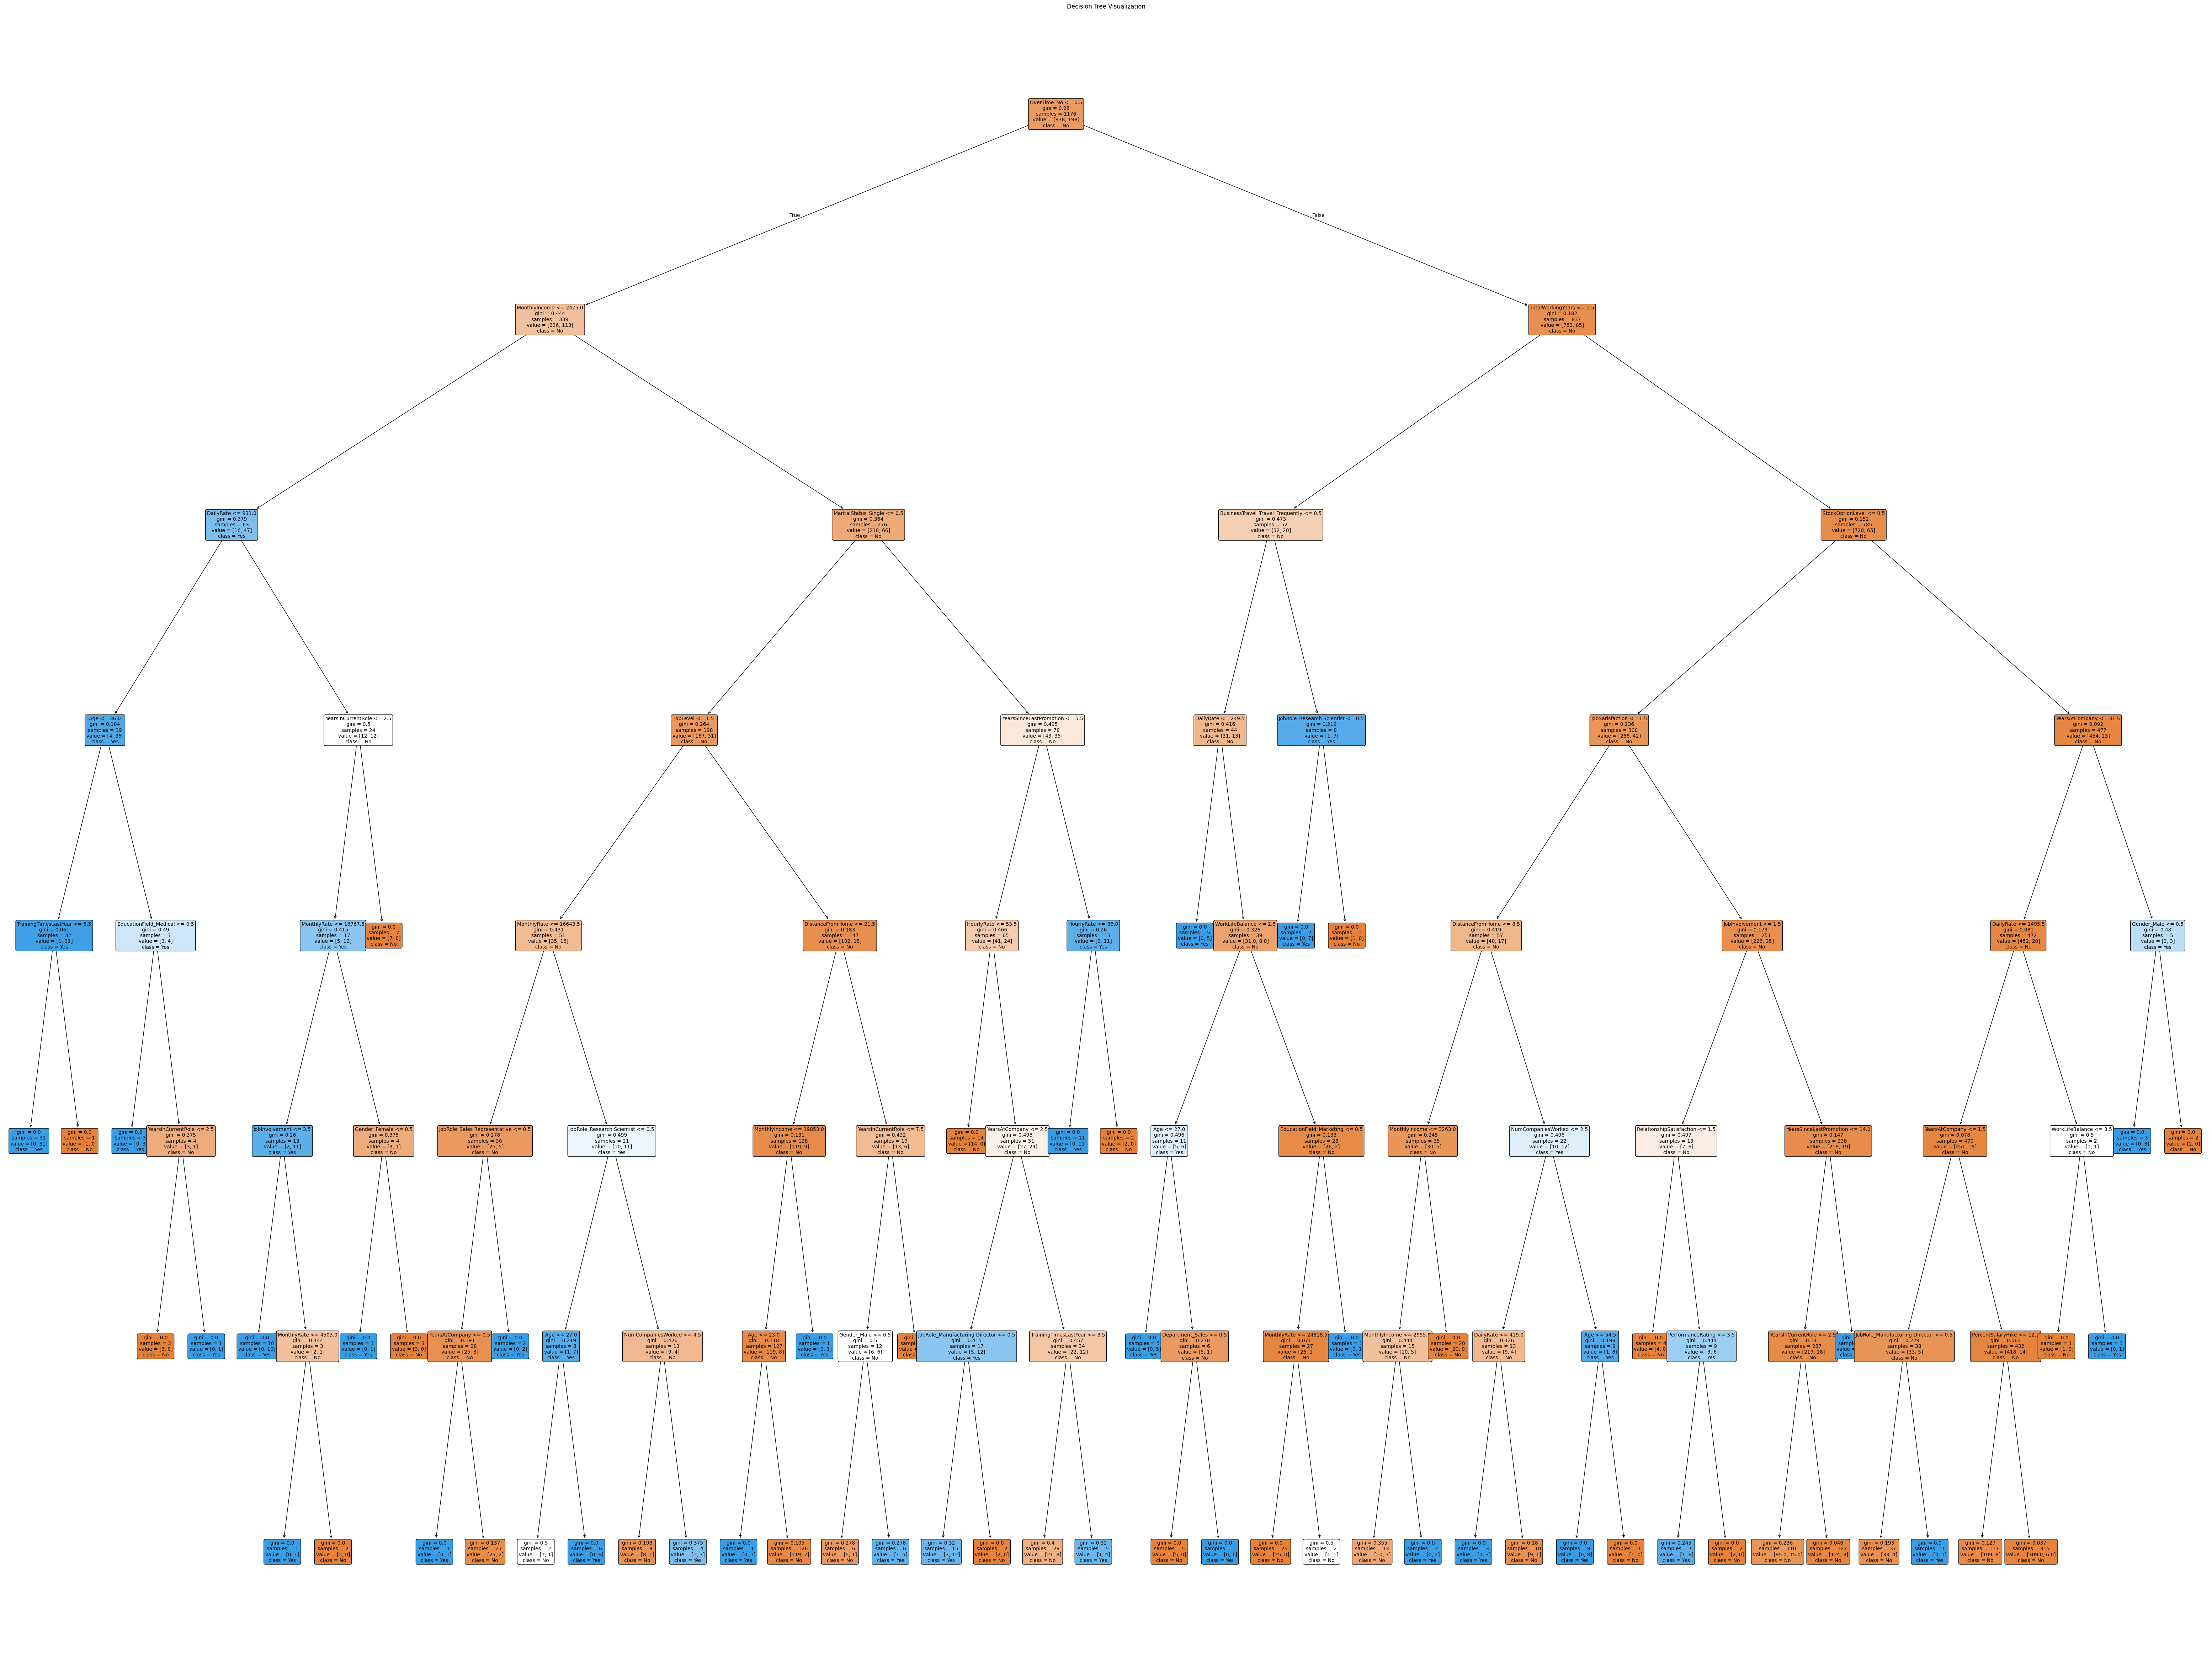

In [ ]:
# Implementing Decision Tree Classifier
decision_tree_model = DecisionTreeClassifier(criterion='gini', max_depth = 7, random_state=42)
decision_tree_model.fit(X_train, y_train)

# Predictions on the test set
y_pred_dt = decision_tree_model.predict(X_test)

# Evaluate the model
print("Decision Tree Classifier Accuracy:", accuracy_score(y_test, y_pred_dt))
#accuracy = no.of correctly predicted data / total test data

precisionDT = precision_score(y_test, y_pred_dt, average='weighted') * 100
print(f"Precision Score: {precisionDT:.4f}")
recallDT = recall_score(y_test, y_pred_dt, average='weighted') * 100
print(f"Recall Score: {recallDT:.4f}")
f1DT = f1_score(y_test, y_pred_dt, average='weighted') * 100
print(f"F1 Score: {f1DT:.4f}")

# Visualize the Decision Tree
plt.figure(figsize=(80, 60))
plot_tree(decision_tree_model, feature_names=X.columns, class_names=['No', 'Yes'], filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree Visualization')
plt.show()

# Random forest

Random Forest Classifier Accuracy: 0.8741496598639455
Precision Score: 85.9166
Recall Score: 87.4150
F1 Score: 82.6973


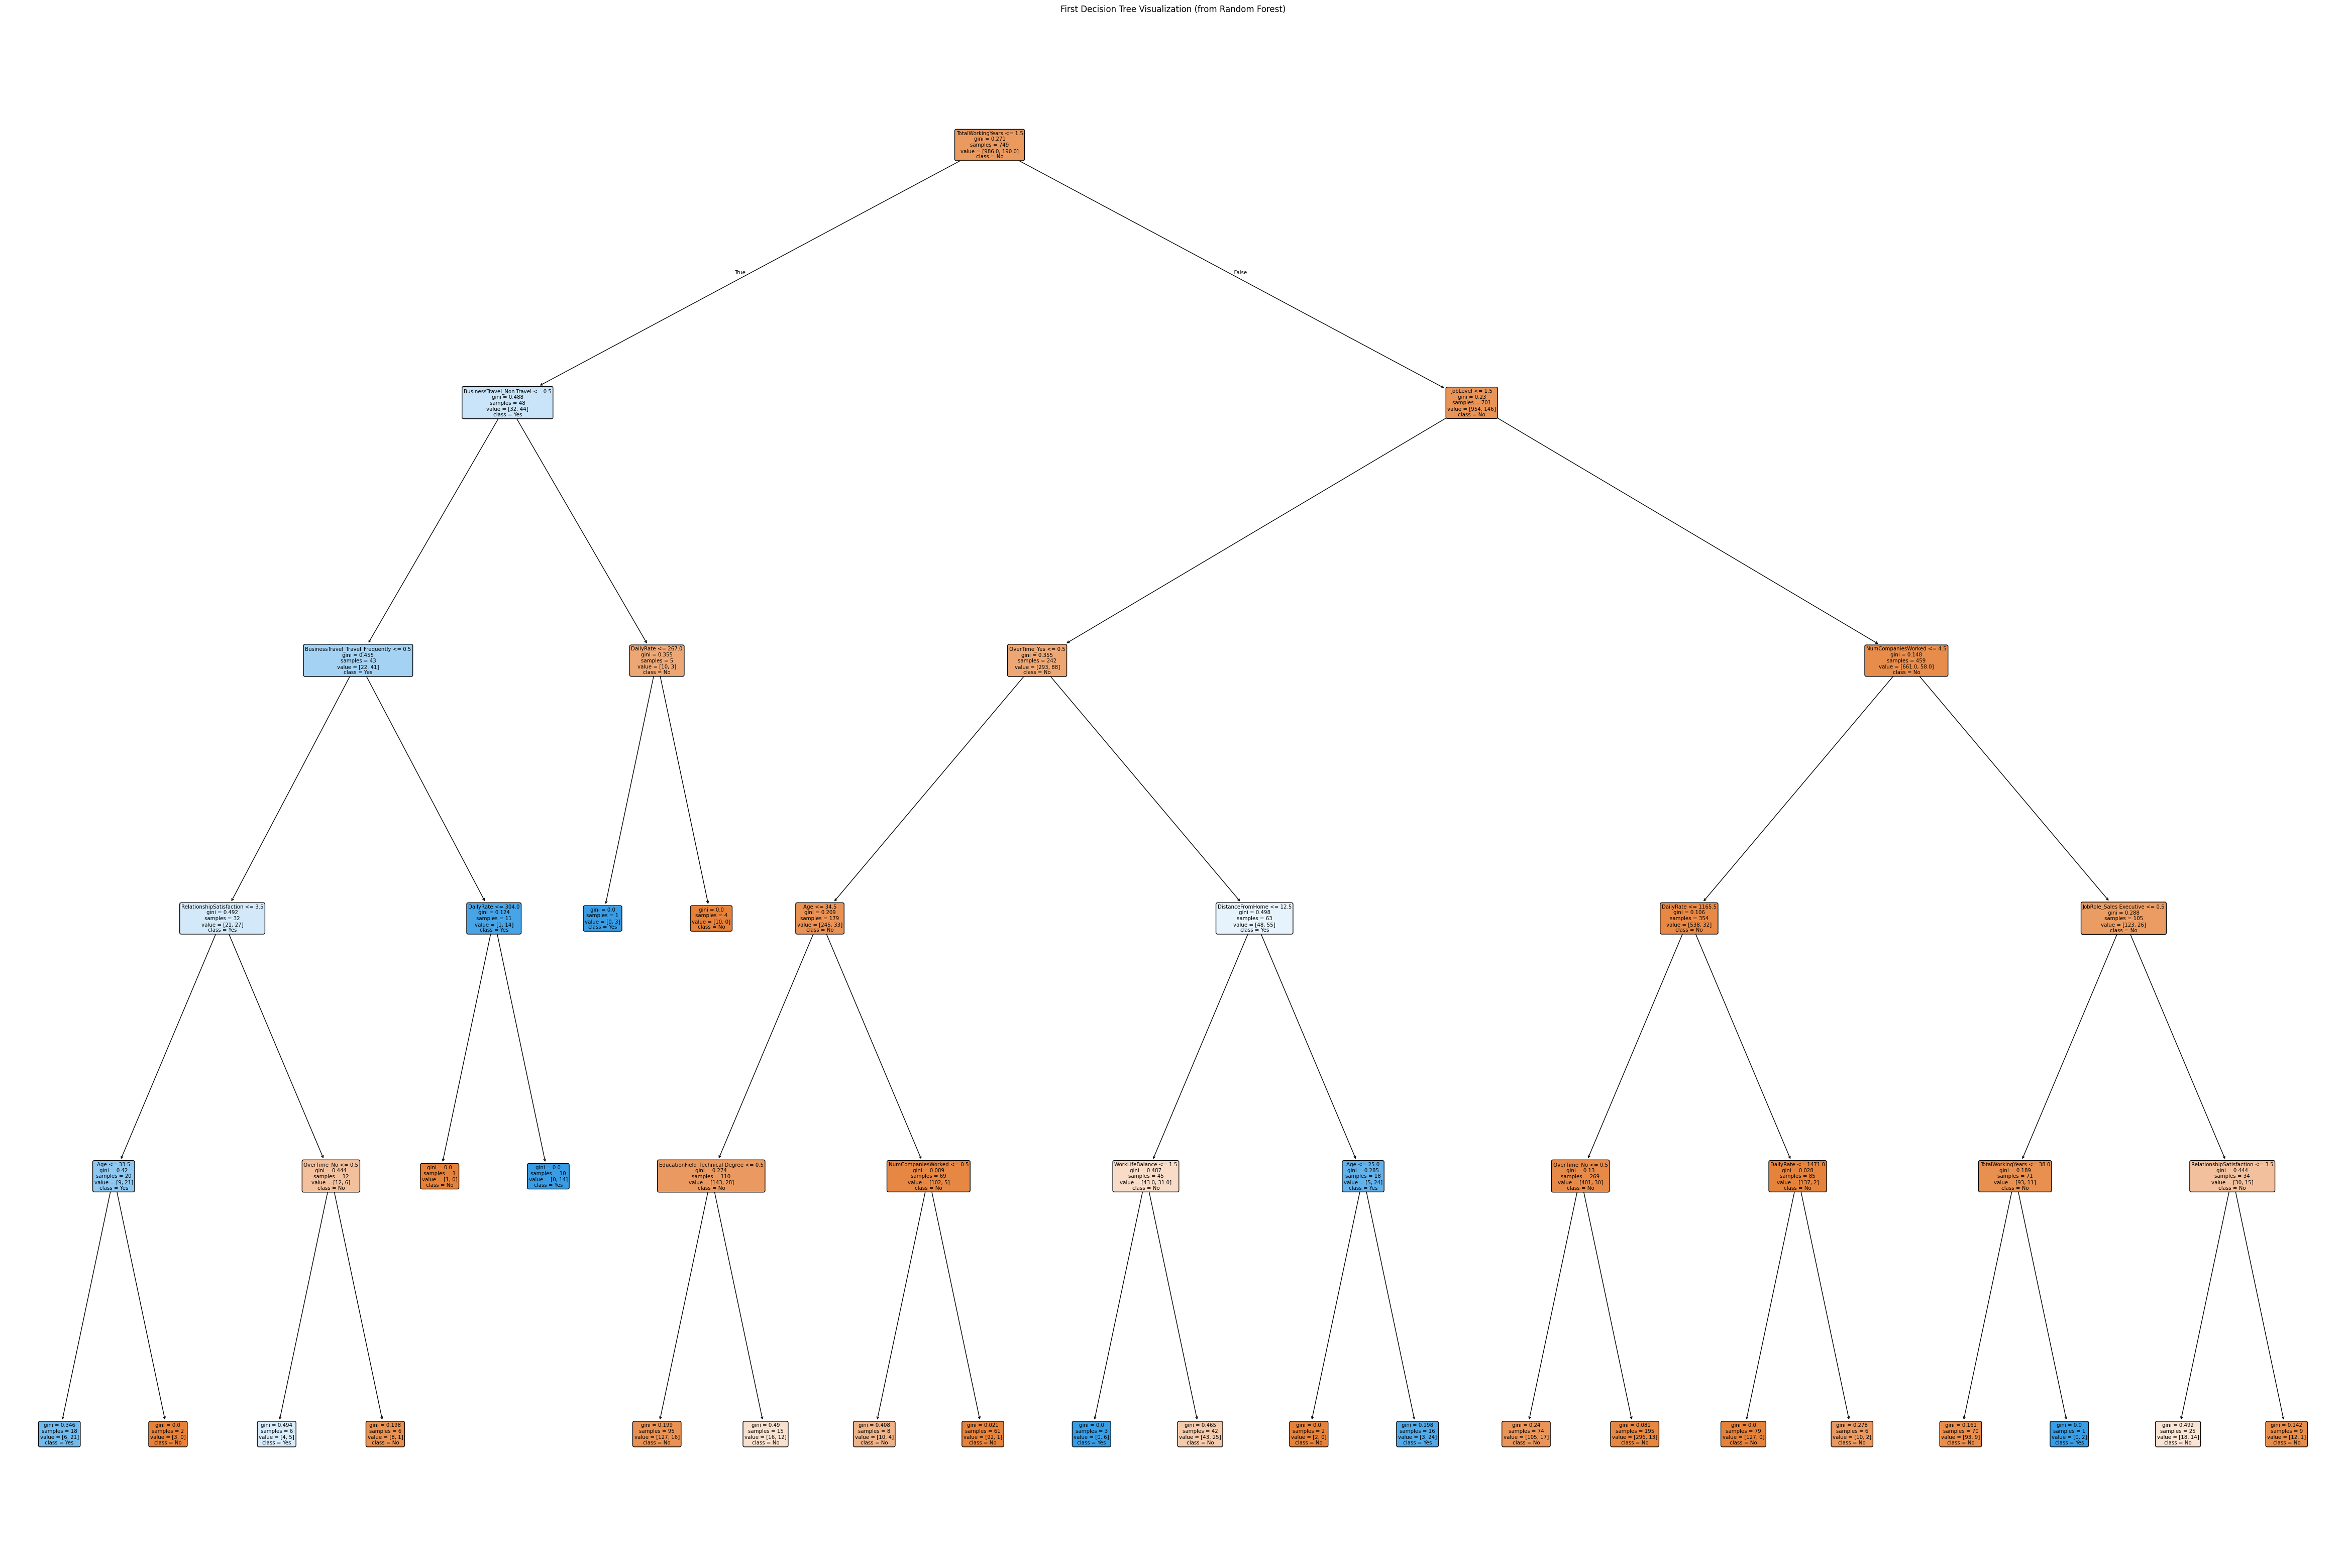

In [ ]:
# Implementing Random Forest Classifier
random_forest_model = RandomForestClassifier(n_estimators=100, max_depth=5, criterion='gini', bootstrap=True, random_state=42)
random_forest_model.fit(X_train, y_train)

# Predictions on the test set
y_pred_rf = random_forest_model.predict(X_test)

# Evaluate the model
print("Random Forest Classifier Accuracy:", accuracy_score(y_test, y_pred_rf))

precisionRF = precision_score(y_test, y_pred_rf, average='weighted') * 100
print(f"Precision Score: {precisionRF:.4f}")
recallRF = recall_score(y_test, y_pred_rf, average='weighted') * 100
print(f"Recall Score: {recallRF:.4f}")
f1RF = f1_score(y_test, y_pred_rf, average='weighted') * 100
print(f"F1 Score: {f1RF:.4f}")

# Visualize one of the decision trees (first tree) in the Forest
plt.figure(figsize=(60, 40))
plot_tree(random_forest_model.estimators_[0], feature_names=X.columns, class_names=['No', 'Yes'], filled=True, rounded=True)
plt.title('First Decision Tree Visualization (from Random Forest)')
plt.show()


# Logistic Regression

In [ ]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

#check for accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8571428571428571


In [ ]:
to_scale = [
    'Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome',
    'MonthlyRate', 'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear',
    'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager'
]

scaler = StandardScaler() # data won't get biased towards any large value

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[to_scale] = scaler.fit_transform(X_train[to_scale])
X_test_scaled[to_scale] = scaler.transform(X_test[to_scale])


In [ ]:
log_reg_model = LogisticRegression(max_iter=1000, random_state=42)
log_reg_model.fit(X_train_scaled, y_train)

# Predictions on the test set
y_pred_lr = log_reg_model.predict(X_test_scaled)

# Evaluate the model
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))

precisionLR = precision_score(y_test, y_pred_lr, average='weighted') * 100
print(f"Precision Score: {precisionLR:.4f}")
recallLR = recall_score(y_test, y_pred_lr, average='weighted') * 100
print(f"Recall Score: {recallLR:.4f}")
f1LR = f1_score(y_test, y_pred_lr, average='weighted') * 100
print(f"F1 Score: {f1LR:.4f}")


Logistic Regression Accuracy: 0.8945578231292517
Precision Score: 88.4149
Recall Score: 89.4558
F1 Score: 88.7015


# Adaboost

In [ ]:
ada_model = AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)
ada_model.fit(X_train, y_train)
y_pred_ab = ada_model.predict(X_test)

print("AdaBoost (n_estimators=100, lr=0.5)")
print("Accuracy Score:", accuracy_score(y_test, y_pred_ab))

precisionAB = precision_score(y_test, y_pred_ab, average='weighted') * 100
print(f"Precision Score: {precisionAB:.4f}")
recallAB = recall_score(y_test, y_pred_ab, average='weighted') * 100
print(f"Recall Score: {recallAB:.4f}")
f1AB = f1_score(y_test, y_pred_ab, average='weighted') * 100
print(f"F1 Score: {f1AB:.4f}")

AdaBoost (n_estimators=100, lr=0.5)
Accuracy Score: 0.8673469387755102
Precision Score: 82.5255
Recall Score: 86.7347
F1 Score: 82.2738


# KNN

Accuracy Score: 0.8639
Precision Score: 81.5402
Recall Score: 86.3946
F1 Score: 82.0639


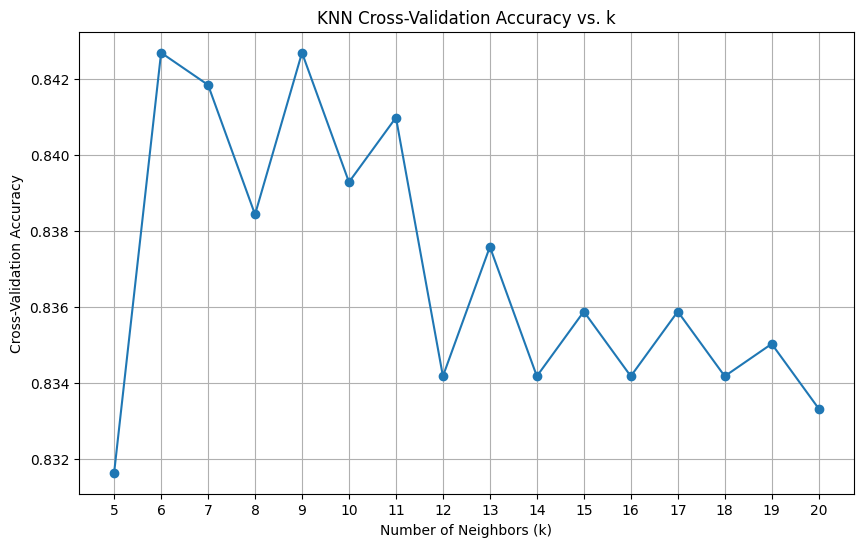

Best k (based on cross-validation): 6 with Accuracy: 0.84


In [ ]:
k = 5  # initial choice of k
knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
knn.fit(X_train_scaled, y_train) # # using scaled training data

# Predictions
y_pred_knn = knn.predict(X_test_scaled)

# Evaluate the model
accuracy_knn = accuracy_score(y_test, y_pred_knn)
print(f"Accuracy Score: {accuracy_knn:.4f}")
precision_knn = precision_score(y_test, y_pred_knn, average='weighted') * 100
print(f"Precision Score: {precision_knn:.4f}")
recall_knn = recall_score(y_test, y_pred_knn, average='weighted') * 100
print(f"Recall Score: {recall_knn:.4f}")
f1_knn = f1_score(y_test, y_pred_knn, average='weighted') * 100
print(f"F1 Score: {f1_knn:.4f}")

# Cross-validation for different k values
cross_val_accuracies = []
k_values = range(5, 21)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5)  # 5-fold cross-validation
    cross_val_accuracies.append(np.mean(scores))

# Plot cross-validation accuracy vs k
plt.figure(figsize=(10, 6))
plt.plot(k_values, cross_val_accuracies, marker='o')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Cross-Validation Accuracy')
plt.title('KNN Cross-Validation Accuracy vs. k')
plt.xticks(k_values)
plt.grid()
plt.show()

# Find the best k
best_k_cv = k_values[np.argmax(cross_val_accuracies)]
print(f'Best k (based on cross-validation): {best_k_cv} '
      f'with Accuracy: {max(cross_val_accuracies):.2f}')

# MLP (Neural Network)

In [ ]:
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=800, random_state=42)
mlp.fit(X_train_scaled, y_train)   # using scaled training data

# Predictions
y_pred = mlp.predict(X_test_scaled)

# Evaluation metrics
accuracyNN = accuracy_score(y_test, y_pred) * 100
precisionNN = precision_score(y_test, y_pred, average='weighted') * 100
recallNN = recall_score(y_test, y_pred, average='weighted') * 100
f1NN = f1_score(y_test, y_pred, average='weighted') * 100

print("Neural Network (MLPClassifier) Results")
print(f"Accuracy: {accuracyNN:.2f}%")
print(f"Precision: {precisionNN:.2f}%")
print(f"Recall: {recallNN:.2f}%")
print(f"F1 Score: {f1NN:.2f}%")

# Correct vs Wrong predictions
correct = np.sum(np.array(y_test) == np.array(y_pred))
total = len(y_test)
wrong = total - correct
print(f"Correct Predictions: {correct}")
print(f"Wrong Predictions: {wrong}")

Neural Network (MLPClassifier) Results
Accuracy: 87.07%
Precision: 86.00%
Recall: 87.07%
F1 Score: 86.44%
Correct Predictions: 256
Wrong Predictions: 38
